# 04 去掉额外余量、收紧误差界：本文方法 vs EKF 3σ

目的：01–03 中 EKF 3σ 在声明误差范围内没有撞墙，因为它越出 3σ 的部分被三项额外余量
（桥墙配准 0.08 m、采样保护 0.05 m、安全余量 0.15 m）吸收了。这里把余量去掉、并收紧本文误差界，
看两种方法的差别能否在实验中显现。所有方法同一设置（`bridge_sim/ext.py: VARIANTS`）：

| 变体 | 改动 |
|---|---|
| `base` | 01–03 的原设置 |
| `margins0` | 三项额外余量全部置 0；同时真实桥墙配准误差置 0（海图准确），保证去掉配准余量后 A1–A2 仍成立 |
| `tight` | 本文误差盒收紧（`TightBound`）：射流梯度耦合项改用北向不确定区间内的局部最大梯度（原为全局最大梯度）；艏向误差项的水速余量 0.20 → 0.05 m/s（最坏世界实测对水速度最多比过桥航速高 0.012 m/s）。仍是最坏情况界 |
| `tight_margins0` | 两者同时 |

EKF 3σ 不受 `tight` 影响（它本来就用局部梯度，也不用水速余量），只受 `margins0` 影响。

**误差界逐项分解（最坏世界、18 m 桥、断星段东向，单位 m）**：射流幅值误差 1.56–1.77，艏向 0.22–0.25，
背景流 0.20–0.23，梯度耦合 0.18–0.22，横向速度 0.08–0.09，纵向速度 0.07；合计 2.35–2.66。
真实东向误差 1.34–1.74；其中仅射流一项按真实北向位置积分就有 1.48–1.68。
所以射流项本身只放大约 6%，误差盒偏松主要来自其余各项最坏值叠加（约 0.8 m），而真实世界中这些项远没到最坏或相互抵消。
在不放弃“最坏情况界”的前提下，能严格收紧的只有梯度项和水速余量，收益有限；见下文数字。

In [1]:
import sys, time
from pathlib import Path
from dataclasses import replace
ROOT = Path.cwd(); sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from bridge_sim.ext import (sample_scenario, run_batch, pmap, gate_and_oracle, DEFAULT_SCENARIO, VARIANTS)
from bridge_sim.metrics import rates_table, fmt_table, feasible, covered

RES = ROOT/'results'; RES.mkdir(exist_ok=True)
FIG = ROOT/'figures'; FIG.mkdir(exist_ok=True)
WORKERS = 4
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)

def worst_worlds(L, variant):
    out = []
    for sj in (1, -1):
        for so in (1, -1):
            out.append(replace(DEFAULT_SCENARIO, length=float(L), width=8.0, jet_amplitude_error=0.22*sj,
                               current_north_bias=0.010*so, current_east_bias=0.011*so, tide_amplitude=0.004,
                               gyro_bias=0.00055*so, wall_shift=-0.08*sj, initial_cross_track=0.5*so,
                               variant=variant))
    return out

def cached(path, scen, methods, progress=20):
    if path.exists():
        print('loading', path.name); return pd.read_csv(path)
    t0 = time.time()
    df = pd.DataFrame(run_batch(scen, methods, workers=WORKERS, progress_every=progress, log_path=str(RES/'progress.log')))
    df.to_csv(path, index=False); print(f'{path.name}: {len(df)} runs in {time.time()-t0:.0f} s')
    return df

## 1. 入口认证：主实验世界，各变体最长可认证桥长

In [2]:
path = RES/'variants_gate_map.csv'
if path.exists():
    gmap = pd.read_csv(path); print('loading', path.name)
else:
    jobs = [dict(s=replace(DEFAULT_SCENARIO, length=float(L), variant=v), with_oracle=False)
            for v in VARIANTS for L in range(9, 52, 3)]
    gmap = pd.DataFrame(pmap(gate_and_oracle, jobs, workers=WORKERS))
    gmap['variant'] = [j['s'].variant for j in jobs]
    gmap.to_csv(path, index=False)
lim = pd.DataFrame({b: gmap[gmap[f'{b}_admitted'].astype(bool)].groupby('variant')['length'].max()
                    for b in ('box', 'ekf')}).rename(columns={'box': 'proposed (box / tight)', 'ekf': 'EKF 3σ'})
lim.loc[list(VARIANTS)]

loading variants_gate_map.csv


,proposed (box / tight),EKF 3σ
variant,,
base,18.0,33.0
margins0,21.0,36.0
tight,18.0,33.0
tight_margins0,21.0,36.0


## 2. 声明界上的四个最坏世界：闭环运行

In [3]:
WC_L = [18, 21, 24, 27, 30, 33, 36, 39]
scen = [s for v in VARIANTS for L in WC_L for s in worst_worlds(L, v)]
wc = cached(RES/'variants_worst_world.csv', scen, ('filter', 'ekf3s', 'oracle'))
assert 'error' not in wc or wc['error'].isna().all()
wc['world'] = [f"jet{a:+.2f}/other{np.sign(b):+.0f}" for a, b in zip(wc.jet_amplitude_error, wc.current_east_bias)]
agg = wc.groupby(['variant', 'length']).agg(
    feasible_all=('oracle_feasible', 'all'),
    filter_admit=('filter_admitted', 'sum'), filter_coll=('filter_collided', 'sum'),
    filter_minclr=('filter_min_clearance', 'min'),
    ekf_admit=('ekf3s_admitted', 'sum'), ekf_coll=('ekf3s_collided', 'sum'),
    ekf_minclr=('ekf3s_min_clearance', 'min'), ekf_lost=('ekf3s_cert_lost', 'sum'))
agg.loc[list(VARIANTS)].round(3)

loading variants_worst_world.csv


feasible_all  filter_admit  filter_coll  filter_minclr  ekf_admit  ekf_coll  ekf_minclr  ekf_lost
variant        length                                                                                                   
base           18.0            True             4            0          1.234          4         0       0.641         0
               21.0            True             0            0            NaN          4         0       0.568         0
               24.0            True             0            0            NaN          4         0       0.216         0
               27.0            True             0            0            NaN          4         0       0.265         0
               30.0            True             0            0            NaN          4         0       0.346         0
               33.0            True             0            0            NaN          4         0       0.073         0
               36.0           False             0            0            NaN          0         0         NaN         0
               39.0           False             0            0            NaN          0         0         NaN         0
margins0       18.0            True             4            0          1.001          4         0       0.523         0
               21.0            True             4            0          1.011          4         0       0.374         0
               24.0            True             0            0            NaN          4         0       0.046         0
               27.0            True             0            0            NaN          4         0       0.154         0
               30.0            True             0            0            NaN          4         0       0.064         0
               33.0            True             0            0            NaN          4         0       0.016         0
               36.0           False             0            0            NaN          4         1      -0.001         0
               39.0           False             0            0            NaN          0         0         NaN         0
tight          18.0            True             4            0          1.158          4         0       0.641         0
               21.0            True             0            0            NaN          4         0       0.568         0
               24.0            True             0            0            NaN          4         0       0.216         0
               27.0            True             0            0            NaN          4         0       0.265         0
               30.0            True             0            0            NaN          4         0       0.346         0
               33.0            True             0            0            NaN          4         0       0.073         0
               36.0           False             0            0            NaN          0         0         NaN         0
               39.0           False             0            0            NaN          0         0         NaN         0
tight_margins0 18.0            True             4            0          1.427          4         0       0.523         0
               21.0            True             4            0          0.954          4         0       0.374         0
               24.0            True             0            0            NaN          4         0       0.046         0
               27.0            True             0            0            NaN          4         0       0.154         0
               30.0            True             0            0            NaN          4         0       0.064         0
               33.0            True             0            0            NaN          4         0       0.016         0
               36.0           False             0            0            NaN          4         1      -0.001         0
               39.0           

In [4]:
print('Collisions in the worst worlds (4 worlds x', len(WC_L), 'lengths per variant):')
for v in VARIANTS:
    d = wc[wc.variant == v]
    print(f"  {v:15s} filter: admitted {int(d.filter_admitted.sum()):2d}, collided {int(d.filter_collided.sum())}, "
          f"max blind err/bound {d.filter_cov_ratio_E_blind.max():.2f} | "
          f"EKF 3σ: admitted {int(d.ekf3s_admitted.sum()):2d}, collided {int(d.ekf3s_collided.sum())}, "
          f"max blind err/3σ {d.ekf3s_cov_ratio_E_blind.max():.2f}")
cols = ['variant', 'length', 'world', 'oracle_best_clearance', 'ekf3s_transit_speed', 'ekf3s_min_clearance',
        'ekf3s_impact_time', 'ekf3s_cov_ratio_E_blind']
wc.loc[wc.ekf3s_collided.astype(bool), cols].round(3)

Collisions in the worst worlds (4 worlds x 8 lengths per variant):
  base            filter: admitted  4, collided 0, max blind err/bound 0.76 | EKF 3σ: admitted 24, collided 0, max blind err/3σ 1.32
  margins0        filter: admitted  8, collided 0, max blind err/bound 0.79 | EKF 3σ: admitted 28, collided 1, max blind err/3σ 1.32
  tight           filter: admitted  4, collided 0, max blind err/bound 0.78 | EKF 3σ: admitted 24, collided 0, max blind err/3σ 1.32
  tight_margins0  filter: admitted  8, collided 0, max blind err/bound 0.80 | EKF 3σ: admitted 28, collided 1, max blind err/3σ 1.32


,variant,length,world,oracle_best_clearance,ekf3s_transit_speed,ekf3s_min_clearance,ekf3s_impact_time,ekf3s_cov_ratio_E_blind
56,margins0,36.0,jet+0.22/other+1,-0.001,1.5,-0.001,43.02,1.13
120,tight_margins0,36.0,jet+0.22/other+1,-0.001,1.5,-0.001,43.02,1.13


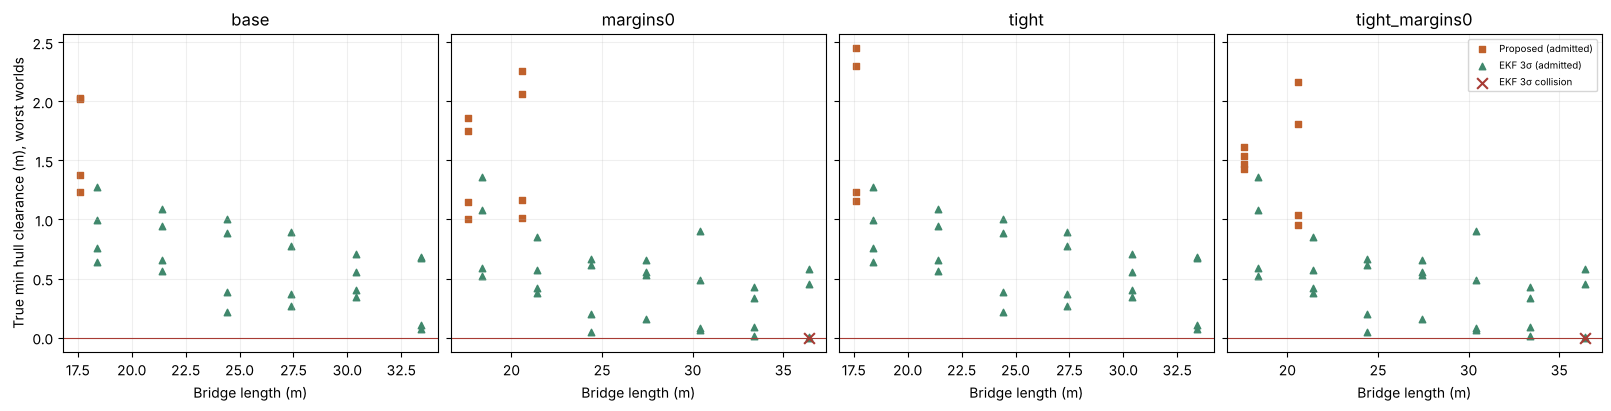

In [5]:
fig, axes = plt.subplots(1, len(VARIANTS), figsize=(16, 4), layout='constrained', sharey=True)
for ax, v in zip(axes, VARIANTS):
    d = wc[wc.variant == v]
    for m, col, mk in (('filter', '#c0612b', 's'), ('ekf3s', '#40886c', '^')):
        adm = d[m + '_admitted'].astype(bool)
        ax.scatter(d.loc[adm, 'length'] + (.4 if m == 'ekf3s' else -.4), d.loc[adm, m + '_min_clearance'].fillna(0),
                   c=col, marker=mk, s=22, label=('Proposed' if m == 'filter' else 'EKF 3σ') + ' (admitted)')
        hit = adm & d[m + '_collided'].astype(bool)
        ax.scatter(d.loc[hit, 'length'] + (.4 if m == 'ekf3s' else -.4), np.zeros(hit.sum()), c='#a83b34', marker='x', s=60,
                   label=None if not hit.any() else ('Proposed' if m == 'filter' else 'EKF 3σ') + ' collision')
    ax.axhline(0, color='#a83b34', lw=.8)
    ax.set(title=v, xlabel='Bridge length (m)'); ax.grid(alpha=.2)
axes[0].set_ylabel('True min hull clearance (m), worst worlds')
axes[-1].legend(fontsize=7)
fig.savefig(FIG/'variants_worst_world.png', dpi=200); fig.savefig(FIG/'variants_worst_world.pdf')
plt.show()

### 细扫 34–38 m（`margins0`，四个最坏世界 + 入口艏向误差 ±0.1 rad，共 8 个世界/桥长）

In [6]:
def worst_worlds8(L, variant):
    return [replace(w, initial_heading_error=h) for w in worst_worlds(L, variant) for h in (0.1, -0.1)]
FINE_L = [34, 35, 36, 37, 38]
fine = cached(RES/'variants_worst_world_fine.csv', [s for L in FINE_L for s in worst_worlds8(L, 'margins0')],
              ('filter', 'ekf3s', 'oracle'), progress=0)
assert 'error' not in fine or fine['error'].isna().all()
fine.groupby('length').agg(feasible=('oracle_feasible', 'sum'), filter_admit=('filter_admitted', 'sum'),
    filter_coll=('filter_collided', 'sum'), ekf_admit=('ekf3s_admitted', 'sum'), ekf_coll=('ekf3s_collided', 'sum'),
    ekf_minclr=('ekf3s_min_clearance', 'min'), n=('seed', 'size'))

loading variants_worst_world_fine.csv


,feasible,filter_admit,filter_coll,ekf_admit,ekf_coll,ekf_minclr,n
length,,,,,,,
34.0,8,0,0,8,0,0.086577,8
35.0,7,0,0,8,0,0.025214,8
36.0,6,0,0,8,4,-0.003103,8
37.0,6,0,0,8,4,-0.002854,8
38.0,4,0,0,8,4,-0.002597,8


## 3. 随机世界 Monte Carlo（桥长 U[15, 50]，与 01 B 部分同一批世界的前 120 个）

In [7]:
def random_length_scenarios(n, variant):
    rng = np.random.default_rng(2027)
    out = []
    for i in range(240):
        L = float(rng.uniform(15.0, 50.0))
        s = sample_scenario(rng, 20000 + i, length=round(L, 2), width=8.0)
        out.append(replace(s, variant=variant))
    return out[:n]
N_MC = 120
mcs = {v: cached(RES/f'variants_mc_{v}.csv', random_length_scenarios(N_MC, v), ('filter', 'ekf3s', 'ilos07', 'oracle'))
       for v in ('margins0', 'tight_margins0')}
base_B = pd.read_csv(RES/'mc_random_length.csv').iloc[:N_MC]
base_bl = pd.read_csv(RES/'baselines_random_length.csv').iloc[:N_MC]
mcs = {'base': pd.concat([base_B, base_bl[[c for c in base_bl if c.startswith('ekf3s_')]]], axis=1), **mcs}
tabs = []
for v, df in mcs.items():
    t = rates_table(df, ['filter', 'ekf3s'], 0.0); t.insert(0, 'variant', v); tabs.append(t)
vt = pd.concat(tabs, ignore_index=True); vt.to_csv(RES/'variants_mc_summary.csv', index=False)
(100*vt.pivot_table(index='metric', columns=['variant', 'method'], values='rate', sort=False)).round(1)

loading variants_mc_margins0.csv
loading variants_mc_tight_margins0.csv


variant                                            base       margins0       tight_margins0      
method                                           filter ekf3s   filter ekf3s         filter ekf3s
metric                                                                                           
accept (放行率)                                       15.8  50.0     21.7  62.5           22.5  62.5
pass (通过率)                                         15.8  50.0     21.7  62.5           22.5  62.5
collision (撞墙率)                                     0.0   0.0      0.0   0.0            0.0   0.0
false accept: admitted & collided (错误放行, 按放行数)      0.0   0.0      0.0   0.0            0.0   0.0
false accept: admitted & infeasible (错误放行, 按放行数)    0.0   0.0      0.0   0.0            0.0   0.0
false reject (误拒, 按能过数)                            83.8  48.7     77.8  35.9           76.9  35.9
bound coverage (误差界覆盖率, 全程)                       100.0   0.0    100.0   0.0          100.0   0.0
certification loss (认证丢失, 按放行数)                     0.0   0.0      0.0   0.0            0.0   0.0
feasible (能过比例)                                    97.5  97.5     97.5  97.5           97.5  97.5

In [8]:
for v, df in mcs.items():
    for m in ('filter', 'ekf3s'):
        adm = df[m + '_admitted'].fillna(False).astype(bool)
        print(f"{v:15s} {m:7s} admitted {adm.sum():3d}/{len(df)}  collided {int(df[m+'_collided'].sum())}  "
              f"min clearance (admitted) {df.loc[adm, m+'_min_clearance'].min():.3f} m  "
              f"max blind err/bound {df[m+'_cov_ratio_E_blind'].max():.2f}")

base            filter  admitted  19/120  collided 0  min clearance (admitted) 1.494 m  max blind err/bound 0.68
base            ekf3s   admitted  60/120  collided 0  min clearance (admitted) 0.783 m  max blind err/bound 1.00
margins0        filter  admitted  26/120  collided 0  min clearance (admitted) 1.264 m  max blind err/bound 0.68
margins0        ekf3s   admitted  75/120  collided 0  min clearance (admitted) 0.299 m  max blind err/bound 1.00
tight_margins0  filter  admitted  27/120  collided 0  min clearance (admitted) 1.203 m  max blind err/bound 0.69
tight_margins0  ekf3s   admitted  75/120  collided 0  min clearance (admitted) 0.299 m  max blind err/bound 1.00


## 结论（数字取自上面的实际运行）

**EKF 3σ 撞墙出现了。** 去掉三项额外余量（`margins0`）后：
- 主实验世界中 EKF 3σ 最长认证 36 m，本文方法 21 m（原设置为 33 m 与 18 m）。
- 四个最坏世界、36 m：EKF 3σ 全部放行，其中 1 次撞墙（t = 43.0 s，射流 +0.22），断星段真实误差为其 3σ 的 1.13 倍。
- 细扫 34–38 m（8 个最坏世界/桥长）：EKF 3σ 每个桥长 8/8 放行，36、37、38 m 各撞墙 4/8，共 12/24；34–35 m 不撞但间隙只剩 0.09 与 0.03 m。本文方法在同样世界里全部拒绝，撞墙 0。
- 撞墙的这些桥，事后 ILOS 用任何航速也过不去（36 m 只有 6/8 个世界能过，38 m 只有 4/8），所以 EKF 3σ 是**错误放行了不可通过的桥**，而不是运气差。

**本文方法在所有设置下撞墙 0**：最坏世界闭环中放行 24 次（四种设置合计），撞墙 0，随机世界 0；断星段真实误差最多为误差界的 0.80 倍。

**随机世界（120 个，桥长 15–50 m）里 EKF 3σ 仍然没有撞墙**，去掉余量后放行率 62.5%，本文方法 21.7–22.5%；
但 EKF 放行者的最小间隙降到 0.30 m。随机世界很少同时碰到所有误差项的最坏值，所以撞墙只在最坏世界显现。
论文里应把“最坏世界 + 去余量”的结果作为 EKF 3σ 不安全的证据，随机世界的结果如实报告为“平均意义上它更激进但没出事”。

**收紧误差界的效果很小。** `tight` 相比 `base` 最长可认证桥长不变（18 m），入口裕度只多 0.06–0.10 m。
逐项分解说明原因：射流幅值误差项占误差盒的约 68%，且只比真实射流影响大约 6%；其余各项是对传感器与海流误差的最坏值，
在严格界的前提下没法再压。去掉余量带来的提升（18 → 21 m）比收紧误差界大得多。
要明显改善保守性，必须减小射流幅值误差界本身（更好的海流图、或进桥前测量射流），或在桥下获得新的位置信息。